# Making mouse predictions

AlphaGenome 2 makes predictions for mouse (*Mus musculus*) as well as human. This tutorial predicts RNA-seq coverage across the mouse alpha-globin cluster in erythroblasts.

Key activities:

*   Load GENCODE vM23 (mm10) gene annotations
*   List mouse reference conditions with `supported_conditions`
*   Call `predict_interval` with `organism=dna_client.Organism.MUS_MUSCULUS`

## Set up

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

In [2]:
# @title Imports
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.models.v2 import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)), then initialize the client:

In [3]:
dna_model = dna_client.create(colab_utils.get_api_key())

Load GENCODE vM23 (mm10) gene annotations and build a `TranscriptExtractor` for the longest protein-coding transcript per gene (see [GENCODE GTF format](https://www.gencodegenes.org/pages/data_format.html)):

In [4]:
# The GTF file contains information on the location of all transcripts.
# Note that we use genome assembly mm10 for mice.
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'mm10/gencode.vM23.annotation.gtf.gz.feather'
)

# Get the longest transcript per gene
gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
gtf_transcripts_longest = gene_annotation.filter_to_longest_transcript(
    gtf_transcripts
)

# Set up transcript extractors using the information in the GTF file.
transcript_extractor = transcript_utils.TranscriptExtractor(
    gtf_transcripts_longest
)

## Make mouse predictions

Other tutorials use the default organism, human (`Organism.HOMO_SAPIENS`). For mouse predictions, pass `organism=dna_client.Organism.MUS_MUSCULUS` to both `supported_conditions` and `predict_interval`, and pass a mouse ontology CURIE via `condition=`. Expression conditioning (`cell_conditioning=`) is supported for human only:

In [5]:
dna_model.supported_conditions(organism=dna_client.Organism.MUS_MUSCULUS)

,condition,biosample_type,biosample_name,atac,cage,dnase,rna_seq,chip_histone,chip_tf,splice_sites,splice_site_usage,splice_junctions,contact_maps,sc_atac,sc_gene_expression,methylation
0,CL:0000038,primary_cell,erythroid progenitor cell,imputed_supported,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,observed,observed,imputed_supported
1,CL:0000048,primary_cell,multi fate stem cell,imputed_supported,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,observed,observed,imputed_supported
2,CL:0000136,primary_cell,adipocyte,imputed_supported,imputed_exploratory,observed,imputed_supported,imputed_supported,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
3,CL:0000187,primary_cell,muscle cell,imputed_supported,imputed_exploratory,imputed_supported,observed,observed,observed,observed,observed,observed,imputed_exploratory,imputed_supported,imputed_supported,imputed_exploratory
4,CL:0000556,primary_cell,megakaryocyte,imputed_supported,imputed_exploratory,imputed_supported,observed,observed,imputed_exploratory,observed,observed,observed,imputed_exploratory,imputed_supported,imputed_supported,imputed_exploratory
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,UBERON:0008345,tissue,ileal epithelium,imputed_exploratory,observed,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory
716,UBERON:0008800,tissue,parietal endoderm,imputed_supported,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,observed,observed,imputed_supported
717,UBERON:0008945,tissue,extraembryonic endoderm,imputed_supported,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,observed,observed,imputed_supported
718,UBERON:0010230,tissue,eyeball of camera-type eye,imputed_exploratory,observed,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory


Call `predict_interval` for a mouse genomic interval around the alpha-globin cluster (chr11:32206003-32337075) in mouse erythroblasts (`CL:0000765`; use `dna_client.SEQUENCE_LENGTH_1MB` for highest accuracy):

In [6]:
interval = genome.Interval.from_str('chr11:32206003-32337075').resize(
    dna_client.SEQUENCE_LENGTH_100KB
)

output = dna_model.predict_interval(
    interval=interval,
    organism=dna_client.Organism.MUS_MUSCULUS,
    requested_outputs=[dna_client.OutputType.RNA_SEQ],
    condition='CL:0000765',
)

output.rna_seq.values.shape

(131072, 12)

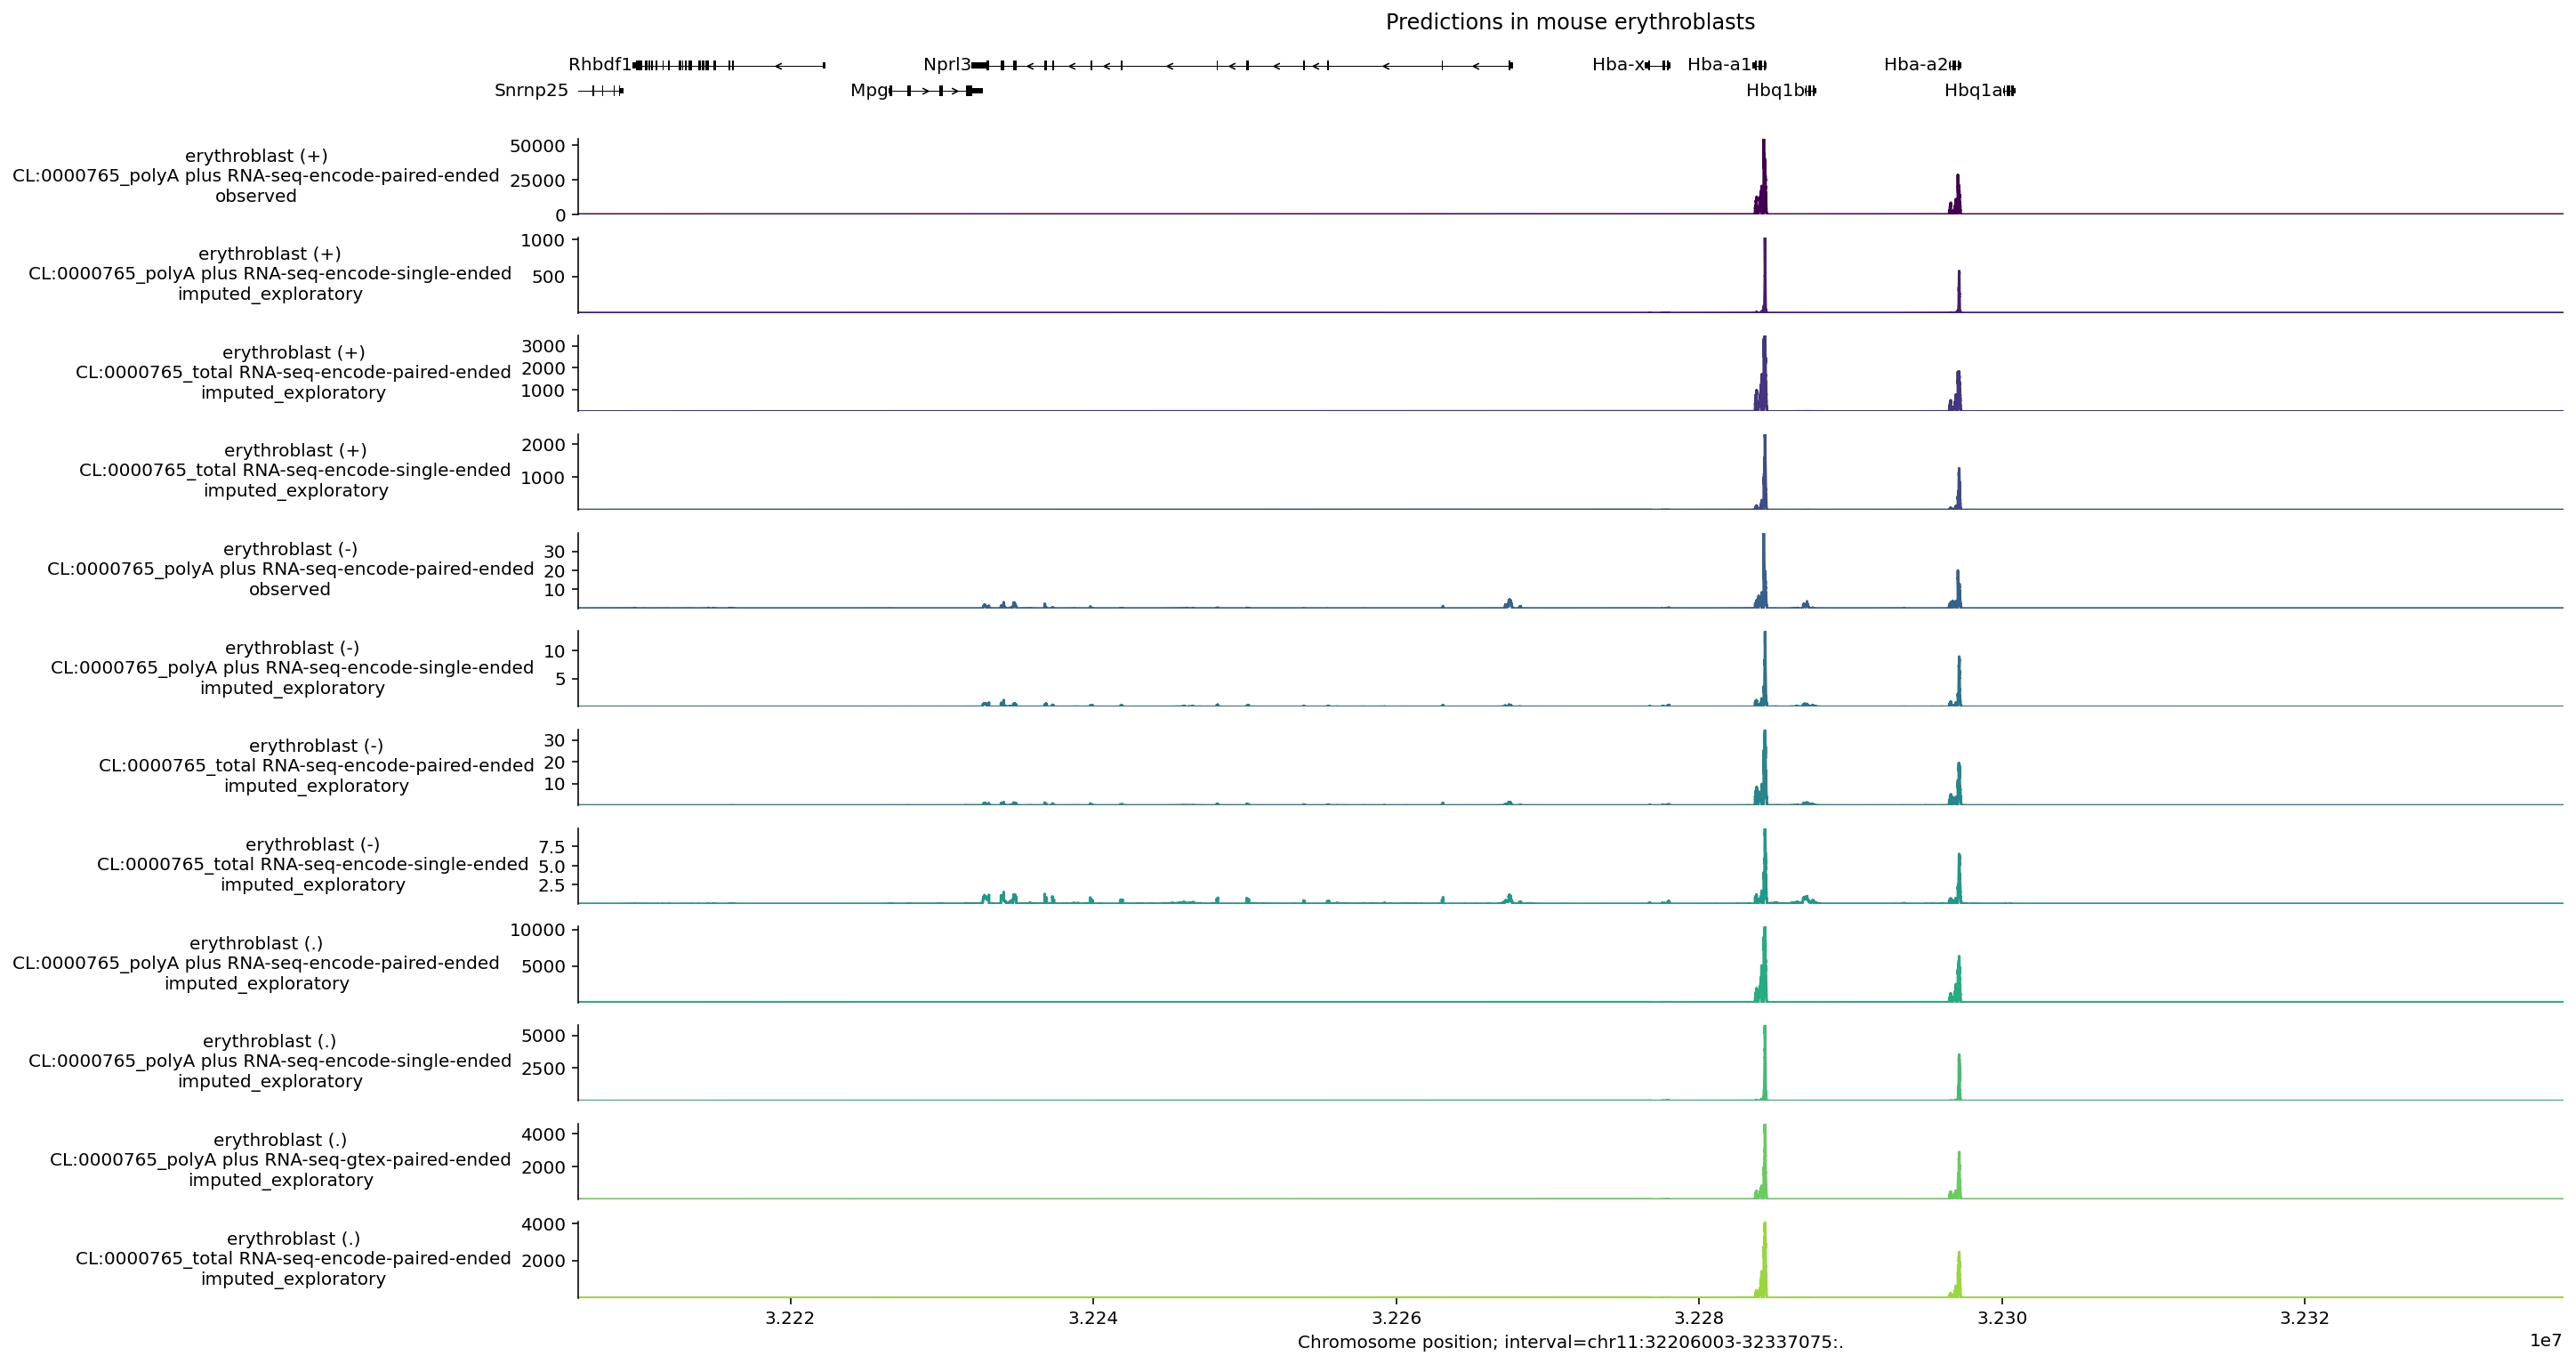

In [7]:
# Extract transcripts
transcripts = transcript_extractor.extract(interval)

# Plot
plot_components.plot(
    components=[
        # Add transcripts to plot
        plot_components.TranscriptAnnotation(transcripts),
        # Add RNA output
        plot_components.Tracks(
            output.rna_seq,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
    ],
    interval=interval,
    title='Predictions in mouse erythroblasts',
)

plt.show()